<a href="https://colab.research.google.com/github/jeremywC4/dinov2-sports-classifier/blob/main/4521_DINOv2_Sports_JeremyWang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate pillow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.2.0 which is incompatible.


In [ ]:
!pip install -q "pillow<12.0"

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import datasets
from torchvision import transforms

from transformers import AutoImageProcessor, AutoModel

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, matthews_corrcoef
from sklearn.model_selection import train_test_split

import random
import glob
from tqdm.auto import tqdm
from PIL import Image
import re


In [ ]:
# Configuration
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.backends.mps.is_available():
    DEVICE = "mps"

CONFIG = {
    "seed": 4521,
    "dinov2_model": "facebook/dinov2-small",
    "embed_batch_size": 128 if DEVICE == "cuda" else 64,
    "mlp_batch_size": 256,
    "mlp_epochs": 30,
    "mlp_patience": 6,
    "mlp_lr": 1e-3,
    "mlp_hidden": [512, 128]
}

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])

In [ ]:
import kagglehub

# Import dataset
path = kagglehub.dataset_download("gpiosenka/sports-classification")
print("Dataset downloaded to:", path)

# Folders
print("Contents:", os.listdir(path))

train_dir = os.path.join(path, "train")
valid_dir = os.path.join(path, "valid")
test_dir  = os.path.join(path, "test")

Using Colab cache for faster access to the 'sports-classification' dataset.
Dataset downloaded to: /kaggle/input/sports-classification
Contents: ['EfficientNetB0-100-(224 X 224)- 98.40.h5', 'sports.csv', 'valid', 'test', 'train']


# Section 1: Dataset and Problem Definition

In [ ]:
# Parse image folder into dataframe
def create_dataset_df(data_dir, split_name):
    records = []
    # filter extensions
    valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff'}

    for class_name in os.listdir(data_dir):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            for file_name in os.listdir(class_path):
                ext = os.path.splitext(file_name)[1].lower()

                if ext in valid_extensions:
                    img_path = os.path.join(class_path, file_name)
                    records.append({
                        "file_path": img_path,
                        "label": class_name,
                        "split": split_name
                    })

    return pd.DataFrame(records)

train_df = create_dataset_df(train_dir, "train")
valid_df = create_dataset_df(valid_dir, "valid")
test_df = create_dataset_df(test_dir, "test")
full_df = pd.concat([train_df, valid_df, test_df], ignore_index=True) # combine

# Dataset info
classes = sorted(train_df["label"].unique())
num_classes = len(classes)

print(f"Total images: {len(full_df)}")
print(f"Train size: {len(train_df)}")
print(f"Validation size: {len(valid_df)}")
print(f"Test size: {len(test_df)}")
print(f"Number of classes: {num_classes}")

# Resplit datasets
train_df, temp_df = train_test_split(full_df, test_size=0.20, stratify=full_df['label'], random_state=42)
# 80/10/10 split
valid_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

print()
print(f"New Train Size: {len(train_df)}")
print(f"New Valid Size: {len(valid_df)}")
print(f"New Test Size:  {len(test_df)}")

Total images: 14492
Train size: 13492
Validation size: 500
Test size: 500
Number of classes: 100

New Train Size: 11593
New Valid Size: 1449
New Test Size:  1450


/tmp/ipykernel_29904/578940623.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_dist.head(20), x='class', y='count', palette='viridis')


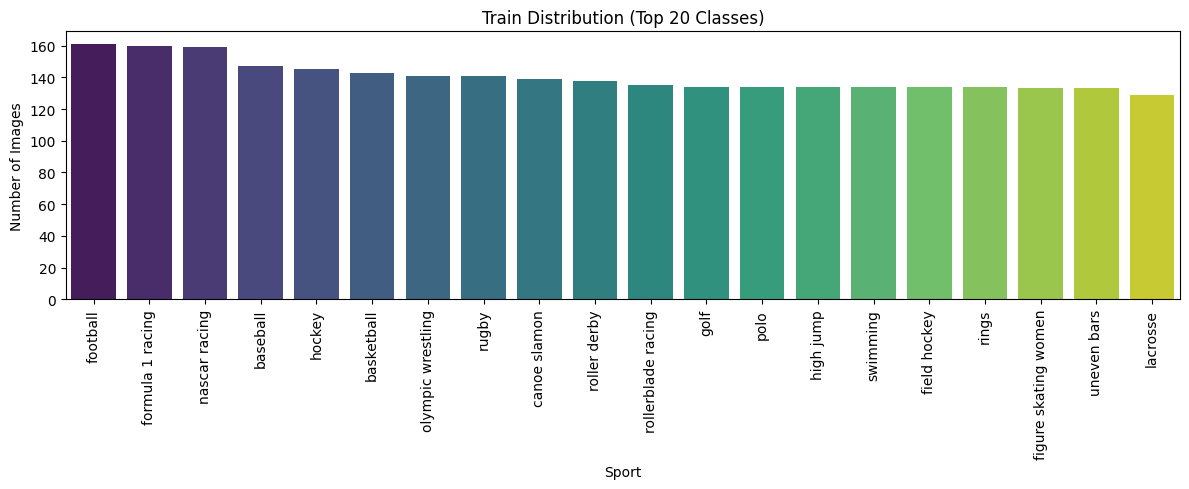

/tmp/ipykernel_29904/578940623.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom20, x='class', y='count', palette='viridis')


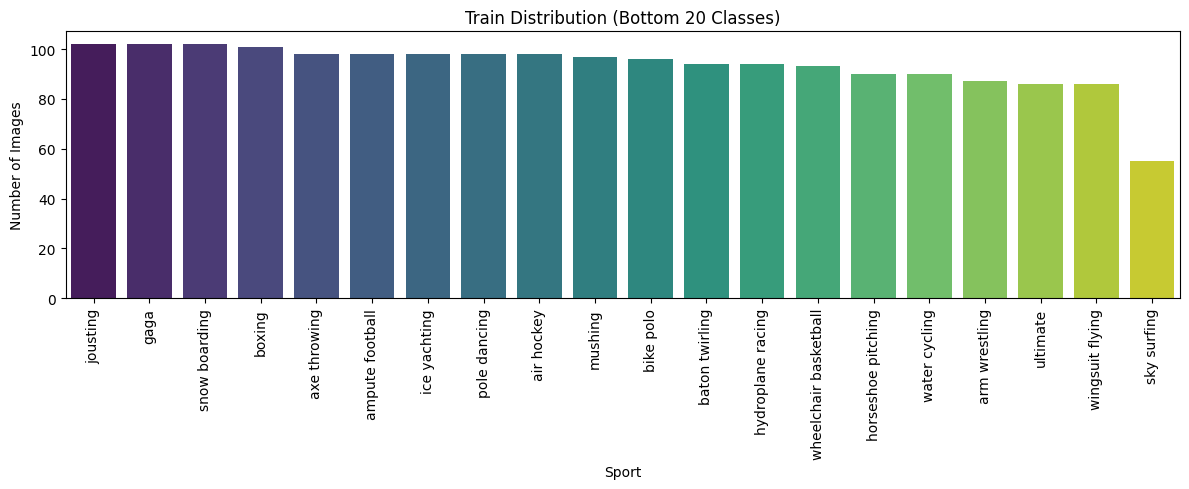

In [ ]:
# Train classes distribution
train_dist = train_df['label'].value_counts().reset_index()
train_dist.columns = ['class', 'count']

# Plot distribution of top 20 classes
plt.figure(figsize=(12, 5))
sns.barplot(data=train_dist.head(20), x='class', y='count', palette='viridis')
plt.title("Train Distribution (Top 20 Classes)")
plt.xticks(rotation=90)
plt.ylabel("Number of Images")
plt.xlabel("Sport")
plt.tight_layout()
plt.show()

bottom20 = train_dist.nsmallest(20, 'count').sort_values(by='count', ascending=False)

# Plot distribution of top 30 classes
plt.figure(figsize=(12, 5))
sns.barplot(data=bottom20, x='class', y='count', palette='viridis')
plt.title("Train Distribution (Bottom 20 Classes)")
plt.xticks(rotation=90)
plt.ylabel("Number of Images")
plt.xlabel("Sport")
plt.tight_layout()
plt.show()

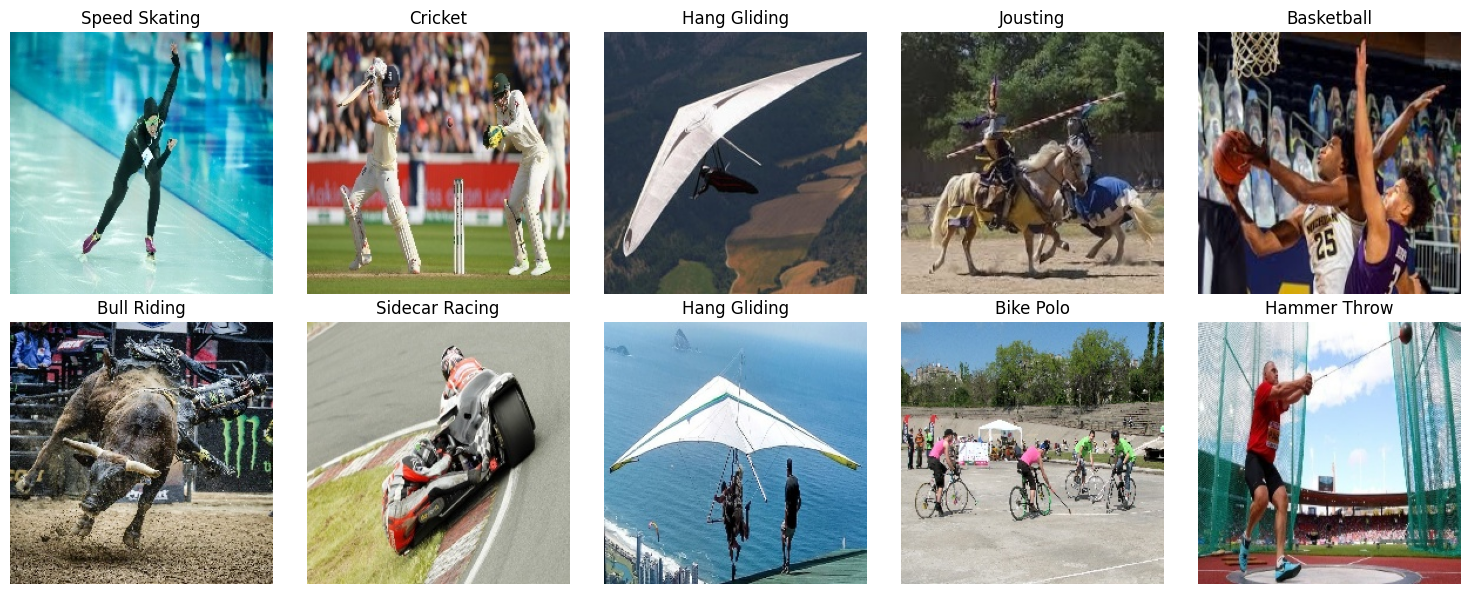

In [ ]:
def show_random(data_dir, num_images=10):
    # All classes in the training folder
    classes = [c for c in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, c))]

    plt.figure(figsize=(15, 6))

    for i in range(num_images):
        # Random sport
        random_class = random.choice(classes)
        class_path = os.path.join(data_dir, random_class)

        # Random image from sport
        images = os.listdir(class_path)
        random_image = random.choice(images)
        img_path = os.path.join(class_path, random_image)

        img = mpimg.imread(img_path)
        ax = plt.subplot(2, 5, i + 1)
        ax.imshow(img)
        ax.set_title(random_class.replace('_', ' ').title())
        ax.axis('off')

    plt.tight_layout()
    plt.show()


show_random(train_dir, num_images=10)

# Section 2: Embedding Model + Transfer Learning

In [ ]:
# Load frozen DINOv2 backbone for embedding extraction
processor = AutoImageProcessor.from_pretrained(CONFIG["dinov2_model"])
embedding_model = AutoModel.from_pretrained(CONFIG["dinov2_model"]).to(DEVICE)
embedding_model.eval() # Freeze backbone

# Data augmentation
test_augmentations = transforms.Compose([
    transforms.RandomRotation(degrees=30), # angled camera
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1), # bad lighting
    transforms.GaussianBlur(kernel_size=(7, 11), sigma=(1.0, 3.0)), # motion blur/unfocused
])

# Custom pytorch dataset
class DataFrameImageDataset(Dataset):
    def __init__(self, df, class_to_idx, transform=None):
        self.df = df.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'file_path']
        label_name = self.df.loc[idx, 'label']
        image = Image.open(img_path).convert('RGB')
        # if data augmentation
        if self.transform:
            image = self.transform(image)
        label_idx = self.class_to_idx[label_name]

        return image, label_idx

# Get pretrained embeddings custom dataset
def extract_embeddings_from_df(df, class_to_idx, processor, model, device, batch_size, transform=None, desc="Extracting"):
    dataset = DataFrameImageDataset(df, class_to_idx, transform=transform)
    num_classes = len(class_to_idx)

    def collate_fn(batch):
        images = [item[0] for item in batch]
        labels = [item[1] for item in batch]
        inputs = processor(images=images, return_tensors="pt")
        return inputs, torch.tensor(labels)

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    all_embeddings = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc=desc):
            inputs = {k: v.to(device) for k, v in inputs.items()}
            outputs = model(**inputs)
            embeddings = outputs.last_hidden_state[:, 0, :]
            all_embeddings.append(embeddings.cpu())
            all_labels.append(labels)

    return torch.cat(all_embeddings), torch.cat(all_labels), num_classes


# Map classes to integer
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

# Extract embeddings for all splits
X_train, y_train, _ = extract_embeddings_from_df(train_df, class_to_idx, processor, embedding_model, DEVICE, CONFIG["embed_batch_size"], desc="Train Set")
X_valid, y_valid, _ = extract_embeddings_from_df(valid_df, class_to_idx, processor, embedding_model, DEVICE, CONFIG["embed_batch_size"], desc="Valid Set")
X_test,  y_test,  _ = extract_embeddings_from_df(test_df,  class_to_idx, processor, embedding_model, DEVICE, CONFIG["embed_batch_size"], desc="Test Set")

# DataLoaders for MLP
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=CONFIG["mlp_batch_size"], shuffle=True)
valid_loader = DataLoader(TensorDataset(X_valid, y_valid), batch_size=CONFIG["mlp_batch_size"], shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=CONFIG["mlp_batch_size"], shuffle=False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Train Set:   0%|          | 0/91 [00:00<?, ?it/s]

Valid Set:   0%|          | 0/12 [00:00<?, ?it/s]

Test Set:   0%|          | 0/12 [00:00<?, ?it/s]

In [ ]:
# Frozen backbone w/ MLP head
class MLPClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()
        layers = []
        current_dim = input_dim

        for h_dim in hidden_dims: # 2 layers
            layers.append(nn.Linear(current_dim, h_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(0.2))
            current_dim = h_dim

        layers.append(nn.Linear(current_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

input_dim = X_train.shape[1] # 384 dimensions
mlp = MLPClassifier(input_dim, CONFIG["mlp_hidden"], num_classes).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp.parameters(), lr=CONFIG["mlp_lr"])

# Training loop
history = {"train_loss": [], "valid_loss": []}
best_val_loss = float("inf")
patience_left = CONFIG["mlp_patience"]
best_model_path = "best_mlp_sports.pt"

print("\nTraining MLP")
for epoch in range(1, CONFIG["mlp_epochs"] + 1):
    mlp.train()
    train_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = mlp(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * xb.size(0)

    train_loss /= len(train_loader.dataset)
    history["train_loss"].append(train_loss)

    # Validation step
    mlp.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, yb in valid_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = mlp(xb)
            loss = criterion(logits, yb)
            val_loss += loss.item() * xb.size(0)

    val_loss /= len(valid_loader.dataset)
    history["valid_loss"].append(val_loss)

    print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Valid Loss: {val_loss:.4f} | Patience: {patience_left}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(mlp.state_dict(), best_model_path)
        patience_left = CONFIG["mlp_patience"]
    else:
        patience_left -= 1

    if patience_left == 0:
        print("Early stopping triggered")
        break

# Load the best model
mlp.load_state_dict(torch.load(best_model_path, map_location=DEVICE))


Training MLP
Epoch 01 | Train Loss: 1.9213 | Valid Loss: 0.3338 | Patience: 6
Epoch 02 | Train Loss: 0.3367 | Valid Loss: 0.1808 | Patience: 6
Epoch 03 | Train Loss: 0.1933 | Valid Loss: 0.1451 | Patience: 6
Epoch 04 | Train Loss: 0.1357 | Valid Loss: 0.1340 | Patience: 6
Epoch 05 | Train Loss: 0.1039 | Valid Loss: 0.1181 | Patience: 6
Epoch 06 | Train Loss: 0.0828 | Valid Loss: 0.1203 | Patience: 6
Epoch 07 | Train Loss: 0.0655 | Valid Loss: 0.1091 | Patience: 5
Epoch 08 | Train Loss: 0.0553 | Valid Loss: 0.0994 | Patience: 6
Epoch 09 | Train Loss: 0.0477 | Valid Loss: 0.1030 | Patience: 6
Epoch 10 | Train Loss: 0.0384 | Valid Loss: 0.1020 | Patience: 5
Epoch 11 | Train Loss: 0.0314 | Valid Loss: 0.1055 | Patience: 4
Epoch 12 | Train Loss: 0.0294 | Valid Loss: 0.1205 | Patience: 3
Epoch 13 | Train Loss: 0.0253 | Valid Loss: 0.1031 | Patience: 2
Epoch 14 | Train Loss: 0.0206 | Valid Loss: 0.1127 | Patience: 1
Early stopping triggered


<All keys matched successfully>

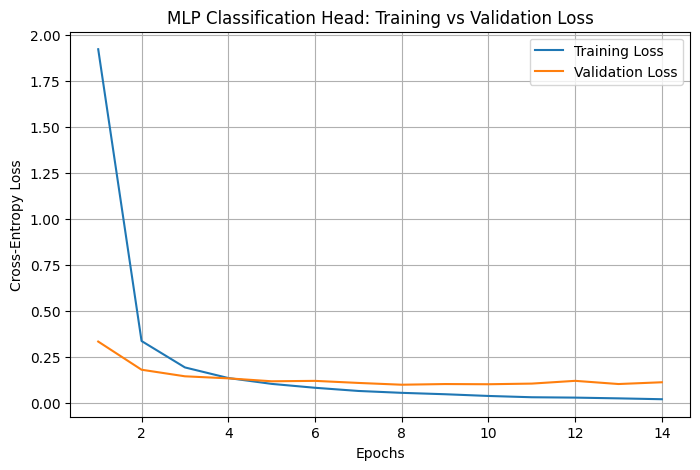

In [ ]:
# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Training Loss")
plt.plot(range(1, len(history["valid_loss"]) + 1), history["valid_loss"], label="Validation Loss")
plt.title("MLP Classification Head: Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Functions modified from cifar final project example
def evaluate_predictions(y_true, y_pred, names, title):
    acc = accuracy_score(y_true, y_pred)
    macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)

    print(f"{title} accuracy: {acc:.4f}")
    print(f"{title} macro-F1: {macro:.4f}")
    print(f"{title} MCC: {mcc:.4f}\n")

    # check if LLaVA strings or MLP ints
    is_string_labels = isinstance(y_true[0], (str, np.str_)) or isinstance(y_pred[0], (str, np.str_))

    if is_string_labels: # LLaVA
        print(classification_report(y_true, y_pred, labels=names, zero_division=0))
        cm = confusion_matrix(y_true, y_pred, labels=names)
    else: # PyTorch MLP
        print(classification_report(y_true, y_pred, target_names=names, zero_division=0))
        int_labels = list(range(len(names)))
        cm = confusion_matrix(y_true, y_pred, labels=int_labels)

    plt.figure(figsize=(24, 20))
    sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=names, yticklabels=names)
    plt.xlabel("Predicted", fontsize=14)
    plt.ylabel("True", fontsize=14)
    plt.title(f"{title} confusion matrix", fontsize=18)
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

    return cm

def top_confusion_pairs(cm, names, k=5):
    pairs = []
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                pairs.append((cm[i, j], i, j))
    pairs.sort(reverse=True)
    return [(count, names[i], names[j]) for count, i, j in pairs[:k]]

DINOv2+MLP accuracy: 0.9669
DINOv2+MLP macro-F1: 0.9657
DINOv2+MLP MCC: 0.9666

                       precision    recall  f1-score   support

           air hockey       1.00      0.92      0.96        12
      ampute football       0.92      1.00      0.96        12
              archery       1.00      1.00      1.00        14
        arm wrestling       1.00      1.00      1.00        11
         axe throwing       0.92      1.00      0.96        12
         balance beam       0.88      0.88      0.88        16
        barell racing       1.00      1.00      1.00        13
             baseball       1.00      0.79      0.88        19
           basketball       0.95      1.00      0.97        18
       baton twirling       1.00      0.92      0.96        12
            bike polo       1.00      1.00      1.00        12
            billiards       1.00      1.00      1.00        16
                  bmx       0.88      1.00      0.94        15
              bobsled       1.00     

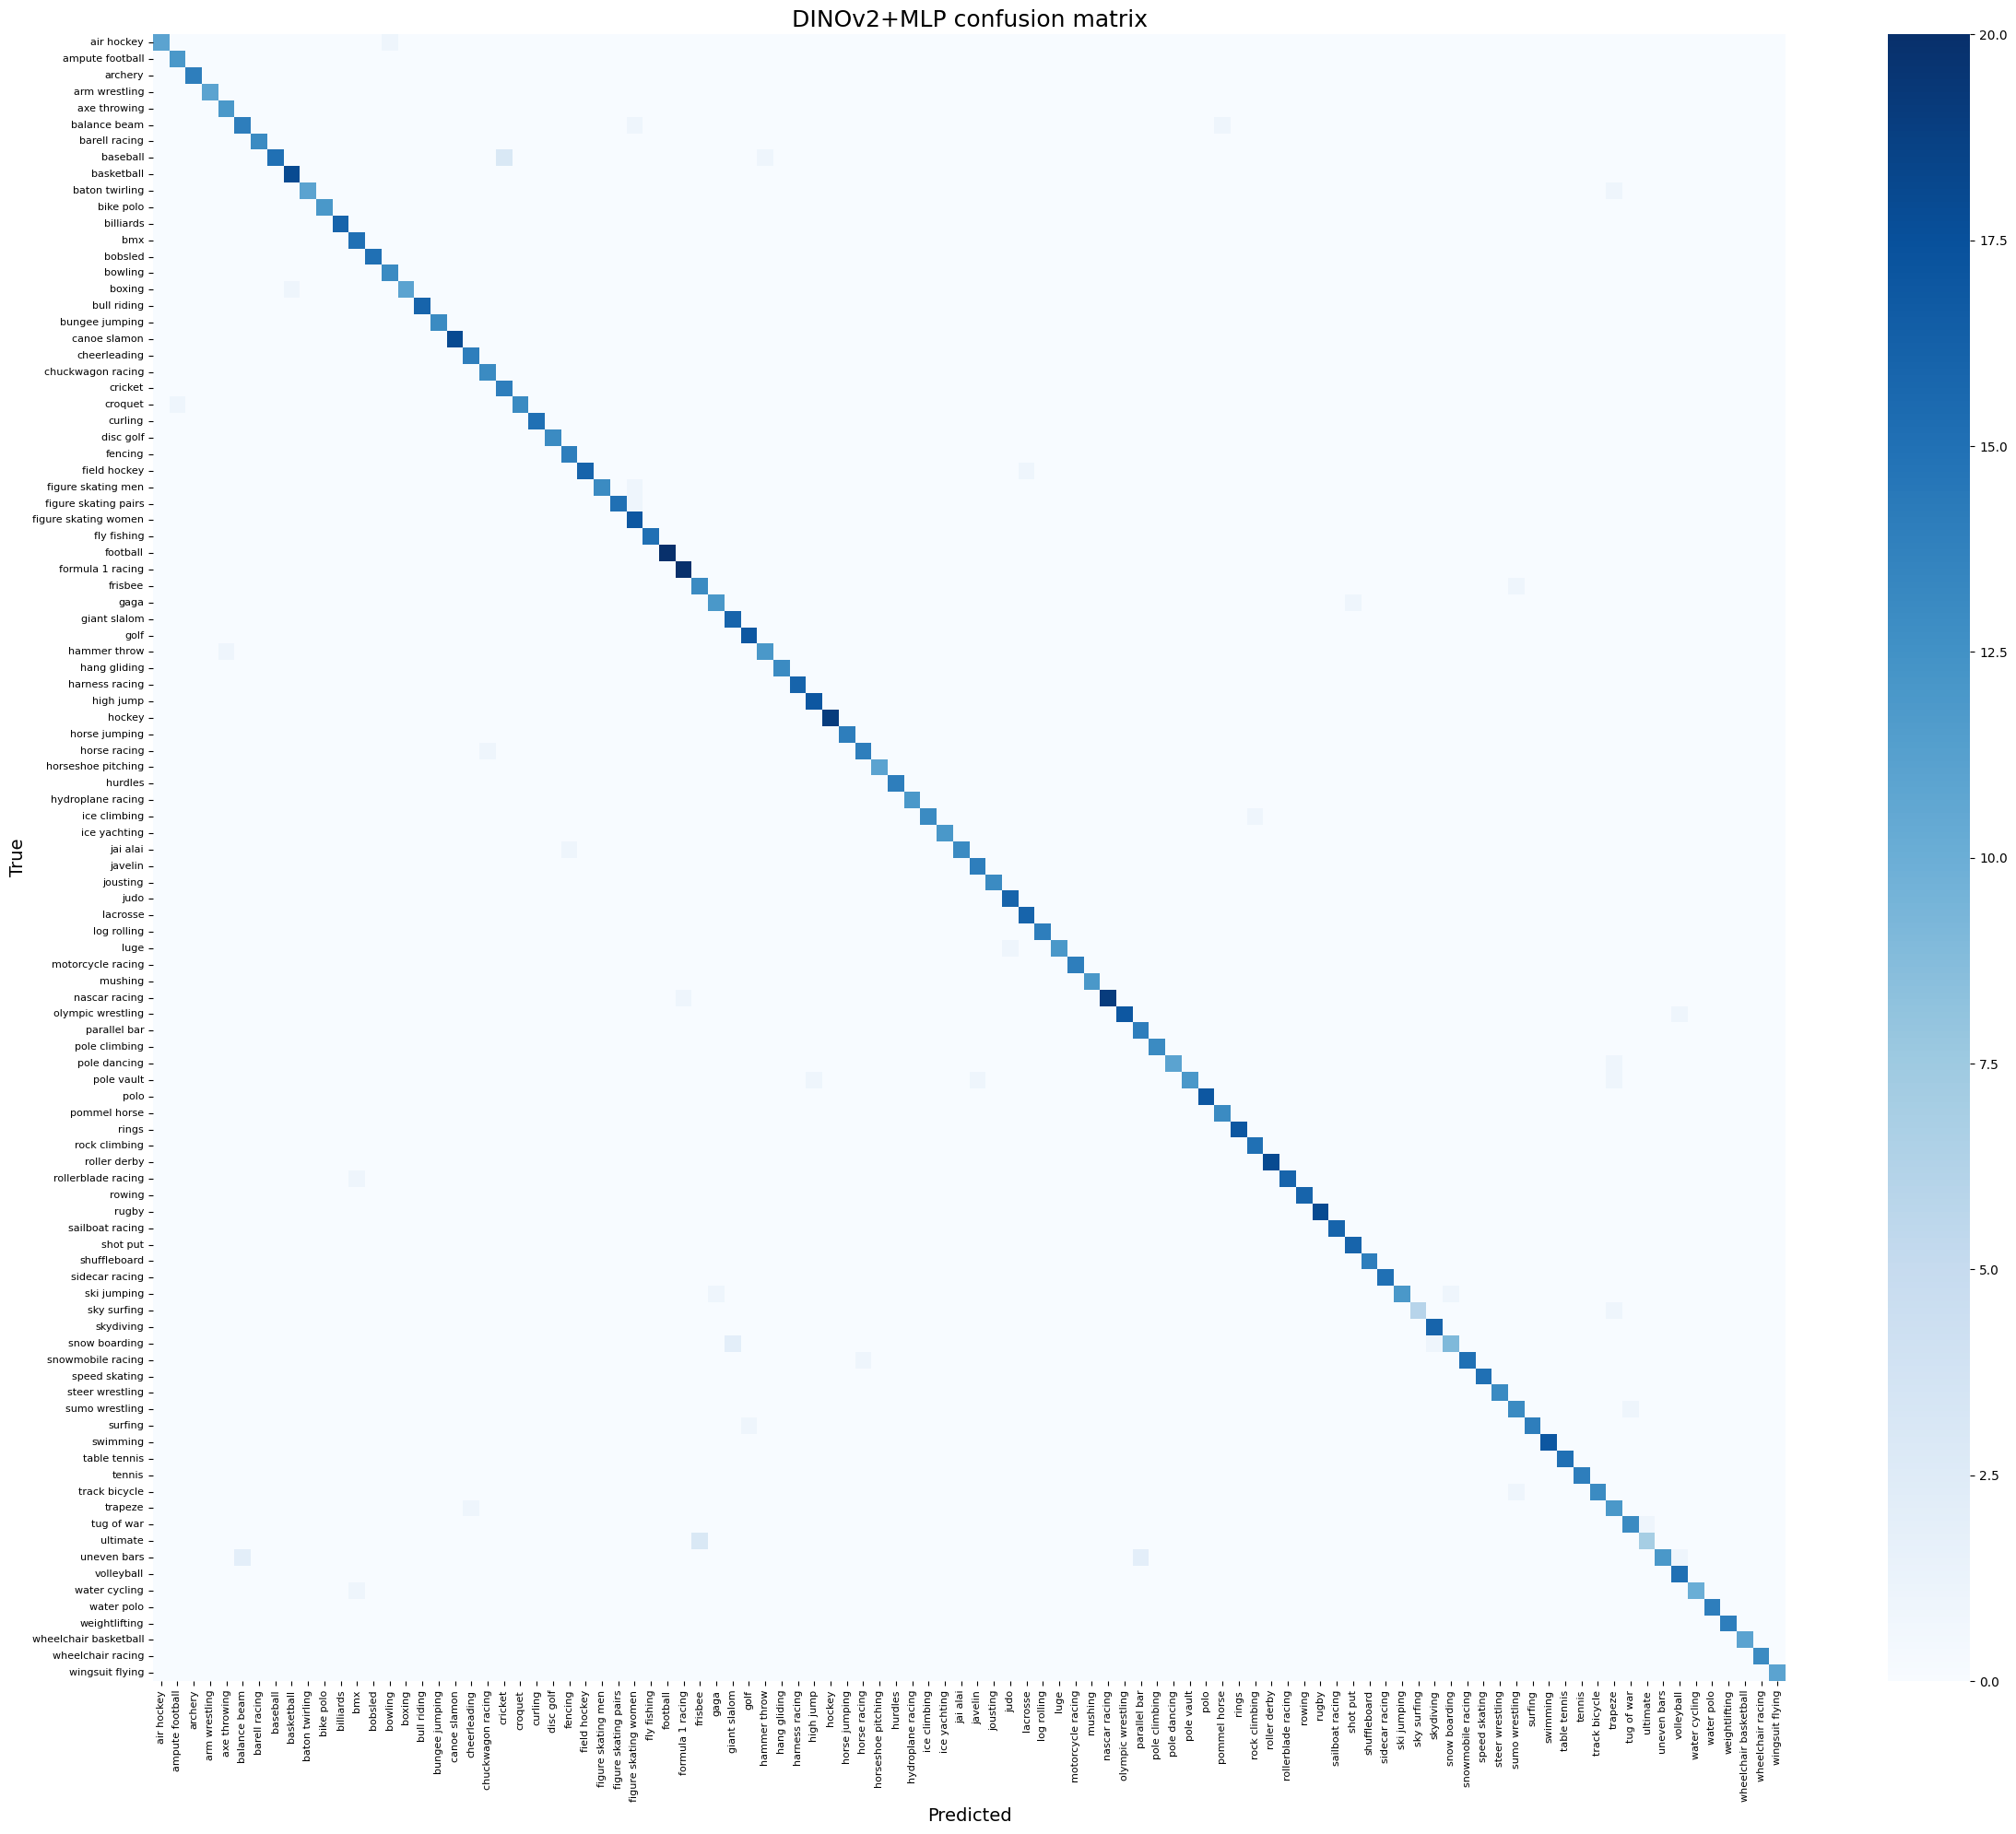


Top confusion pairs (MLP):
            ultimate -> frisbee             : 3
            baseball -> cricket             : 3
         uneven bars -> parallel bar        : 2
         uneven bars -> balance beam        : 2
       snow boarding -> giant slalom        : 2
       water cycling -> bmx                 : 1
         uneven bars -> volleyball          : 1
          tug of war -> ultimate            : 1


In [ ]:
# Get predictions
mlp.eval()
all_preds = []
all_targets = []
all_probs = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        logits = mlp(xb)

        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(yb.numpy())

        probs = F.softmax(logits, dim=1)
        all_probs.extend(probs.cpu().numpy())

y_true = np.array(all_targets)
y_pred = np.array(all_preds)
test_probs = np.array(all_probs)

mlp_cm = evaluate_predictions(y_true, y_pred, classes, "DINOv2+MLP")

print("\nTop confusion pairs (MLP):")
for count, t, p in top_confusion_pairs(mlp_cm, classes, k=8):
    print(f"{t:>20} -> {p:<20}: {count}")

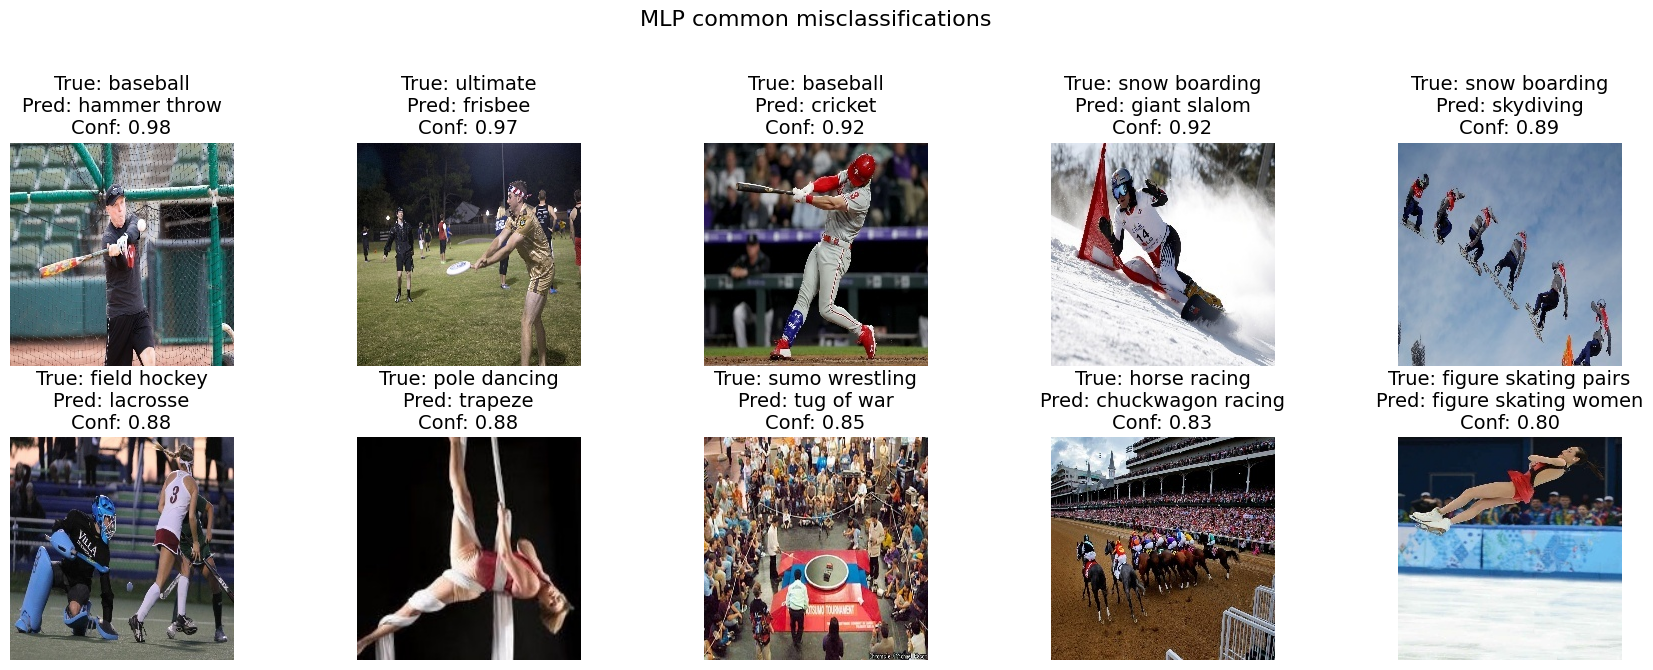

In [ ]:
# Functions modified from cifar final project example
def collect_misclassified_examples(dataset_obj, y_true, y_pred, probs, max_examples=12):
    wrong_idx = np.where(y_true != y_pred)[0]
    records = []
    for i in wrong_idx:
        records.append(
            {
                "idx": int(i),
                "true": int(y_true[i]),
                "pred": int(y_pred[i]),
                "confidence": float(probs[i, int(y_pred[i])]),
            }
        )
    records.sort(key=lambda x: x["confidence"], reverse=True)
    return records[:max_examples]

def show_examples(dataset_obj, examples, names, title, ncols=5):
    if not examples:
        print("No examples to show.")
        return
    n = len(examples)
    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(3.5 * ncols, 3.5 * nrows))
    dataset_obj = dataset_obj.reset_index(drop=True)
    for k, ex in enumerate(examples, start=1):
        img_path = dataset_obj.loc[ex["idx"], 'file_path']
        img = Image.open(img_path).convert('RGB')
        plt.subplot(nrows, ncols, k)
        plt.imshow(img)
        plt.title(
            f"True: {names[ex['true']]}\nPred: {names[ex['pred']]}\nConf: {ex['confidence']:.2f}",
            fontsize=14,
        )
        plt.axis("off")
    plt.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Failure cases
mlp_mis_examples = collect_misclassified_examples(test_df, y_true, y_pred, test_probs, max_examples=15)
show_examples(test_df, mlp_mis_examples[:10], classes, "MLP common misclassifications")

## Section 3: Large-Language Model

In [ ]:
from transformers import pipeline, BitsAndBytesConfig

# compress model to 4-bit, Colab
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

# Load LLaVA pipeline
model_id = "llava-hf/llava-1.5-7b-hf"
pipe = pipeline(
    "image-text-to-text",
    model=model_id,
    model_kwargs={"quantization_config": quantization_config},
    device_map="auto"
)

# Subsampling
num_samples = 200
llm_test_df = test_df.sample(n=num_samples, random_state=4521).reset_index(drop=True)

valid_classes_str = ", ".join(classes)

# Strict prompt
PROMPT = f"""USER: <image>
You are a professional sports classifier. Look at the provided image and identify the sport being played.
You MUST select exactly one sport from the following valid list:
[{valid_classes_str}]

1. Output NOTHING except the exact sport name.
2. Be specific! (e.g., choose 'balance beam' or 'parallel bar' instead of just 'gymnastics', choose 'figure skating women' instead of 'figure skating').
3. Do not add any punctuation or extra words.
ASSISTANT:"""


Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

In [ ]:
y_true_llm = []
y_pred_llm = []
failed_extractions = 0

# LLM inference loop
for idx, row in tqdm(llm_test_df.iterrows(), total=len(llm_test_df)):
    img_path = row['file_path']
    true_label = row['label'].lower()
    img = Image.open(img_path).convert('RGB')

    try:
        # Tokens to 20 for long sports names
        outputs = pipe(img, text=PROMPT, generate_kwargs={"max_new_tokens": 20, "max_length": None})

        raw_output = outputs[0]["generated_text"]
        pred_text = raw_output.split("ASSISTANT:")[-1].strip().lower()
        pred_text = re.sub(r'[^\w\s]', '', pred_text).strip()

        # Search for any of the listed sports in the output
        matched_label = "unknown"
        for sport in classes:
            if sport.replace('_', ' ') in pred_text:
                matched_label = sport
                break

        if matched_label != "unknown":
            y_pred_llm.append(matched_label)
            y_true_llm.append(true_label)
        else:
            print(f"Warning: Could not extract sport from model output: '{pred_text}'")
            y_pred_llm.append("unknown")
            y_true_llm.append(true_label)
            failed_extractions += 1

    except Exception as e:
        print(f"Error on index {idx}: {e}")
        y_pred_llm.append("unknown")
        y_true_llm.append(true_label)


  0%|          | 0/200 [00:00<?, ?it/s]

[transformers] The input data was not formatted as a chat with dicts containing 'role' and 'content' keys, even though this model supports chat. Consider using the chat format for better results. For more information, see https://huggingface.co/docs/transformers/en/chat_templating
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Failed extractions/hallucinations: 55

LLaVA-1.5 accuracy: 0.4750
LLaVA-1.5 macro-F1: 0.3908
LLaVA-1.5 MCC: 0.4917

                       precision    recall  f1-score   support

           air hockey       0.00      0.00      0.00         1
      ampute football       0.33      1.00      0.50         1
              archery       0.50      1.00      0.67         3
        arm wrestling       0.00      0.00      0.00         1
         axe throwing       0.00      0.00      0.00         2
         balance beam       0.00      0.00      0.00         2
        barell racing       0.00      0.00      0.00         3
             baseball       0.75      1.00      0.86         3
           basketball       0.33      1.00      0.50         2
       baton twirling       0.00      0.00      0.00         1
            bike polo       0.00      0.00      0.00         1
            billiards       0.50      1.00      0.67         1
                  bmx       0.33      1.00      0.50         1
 

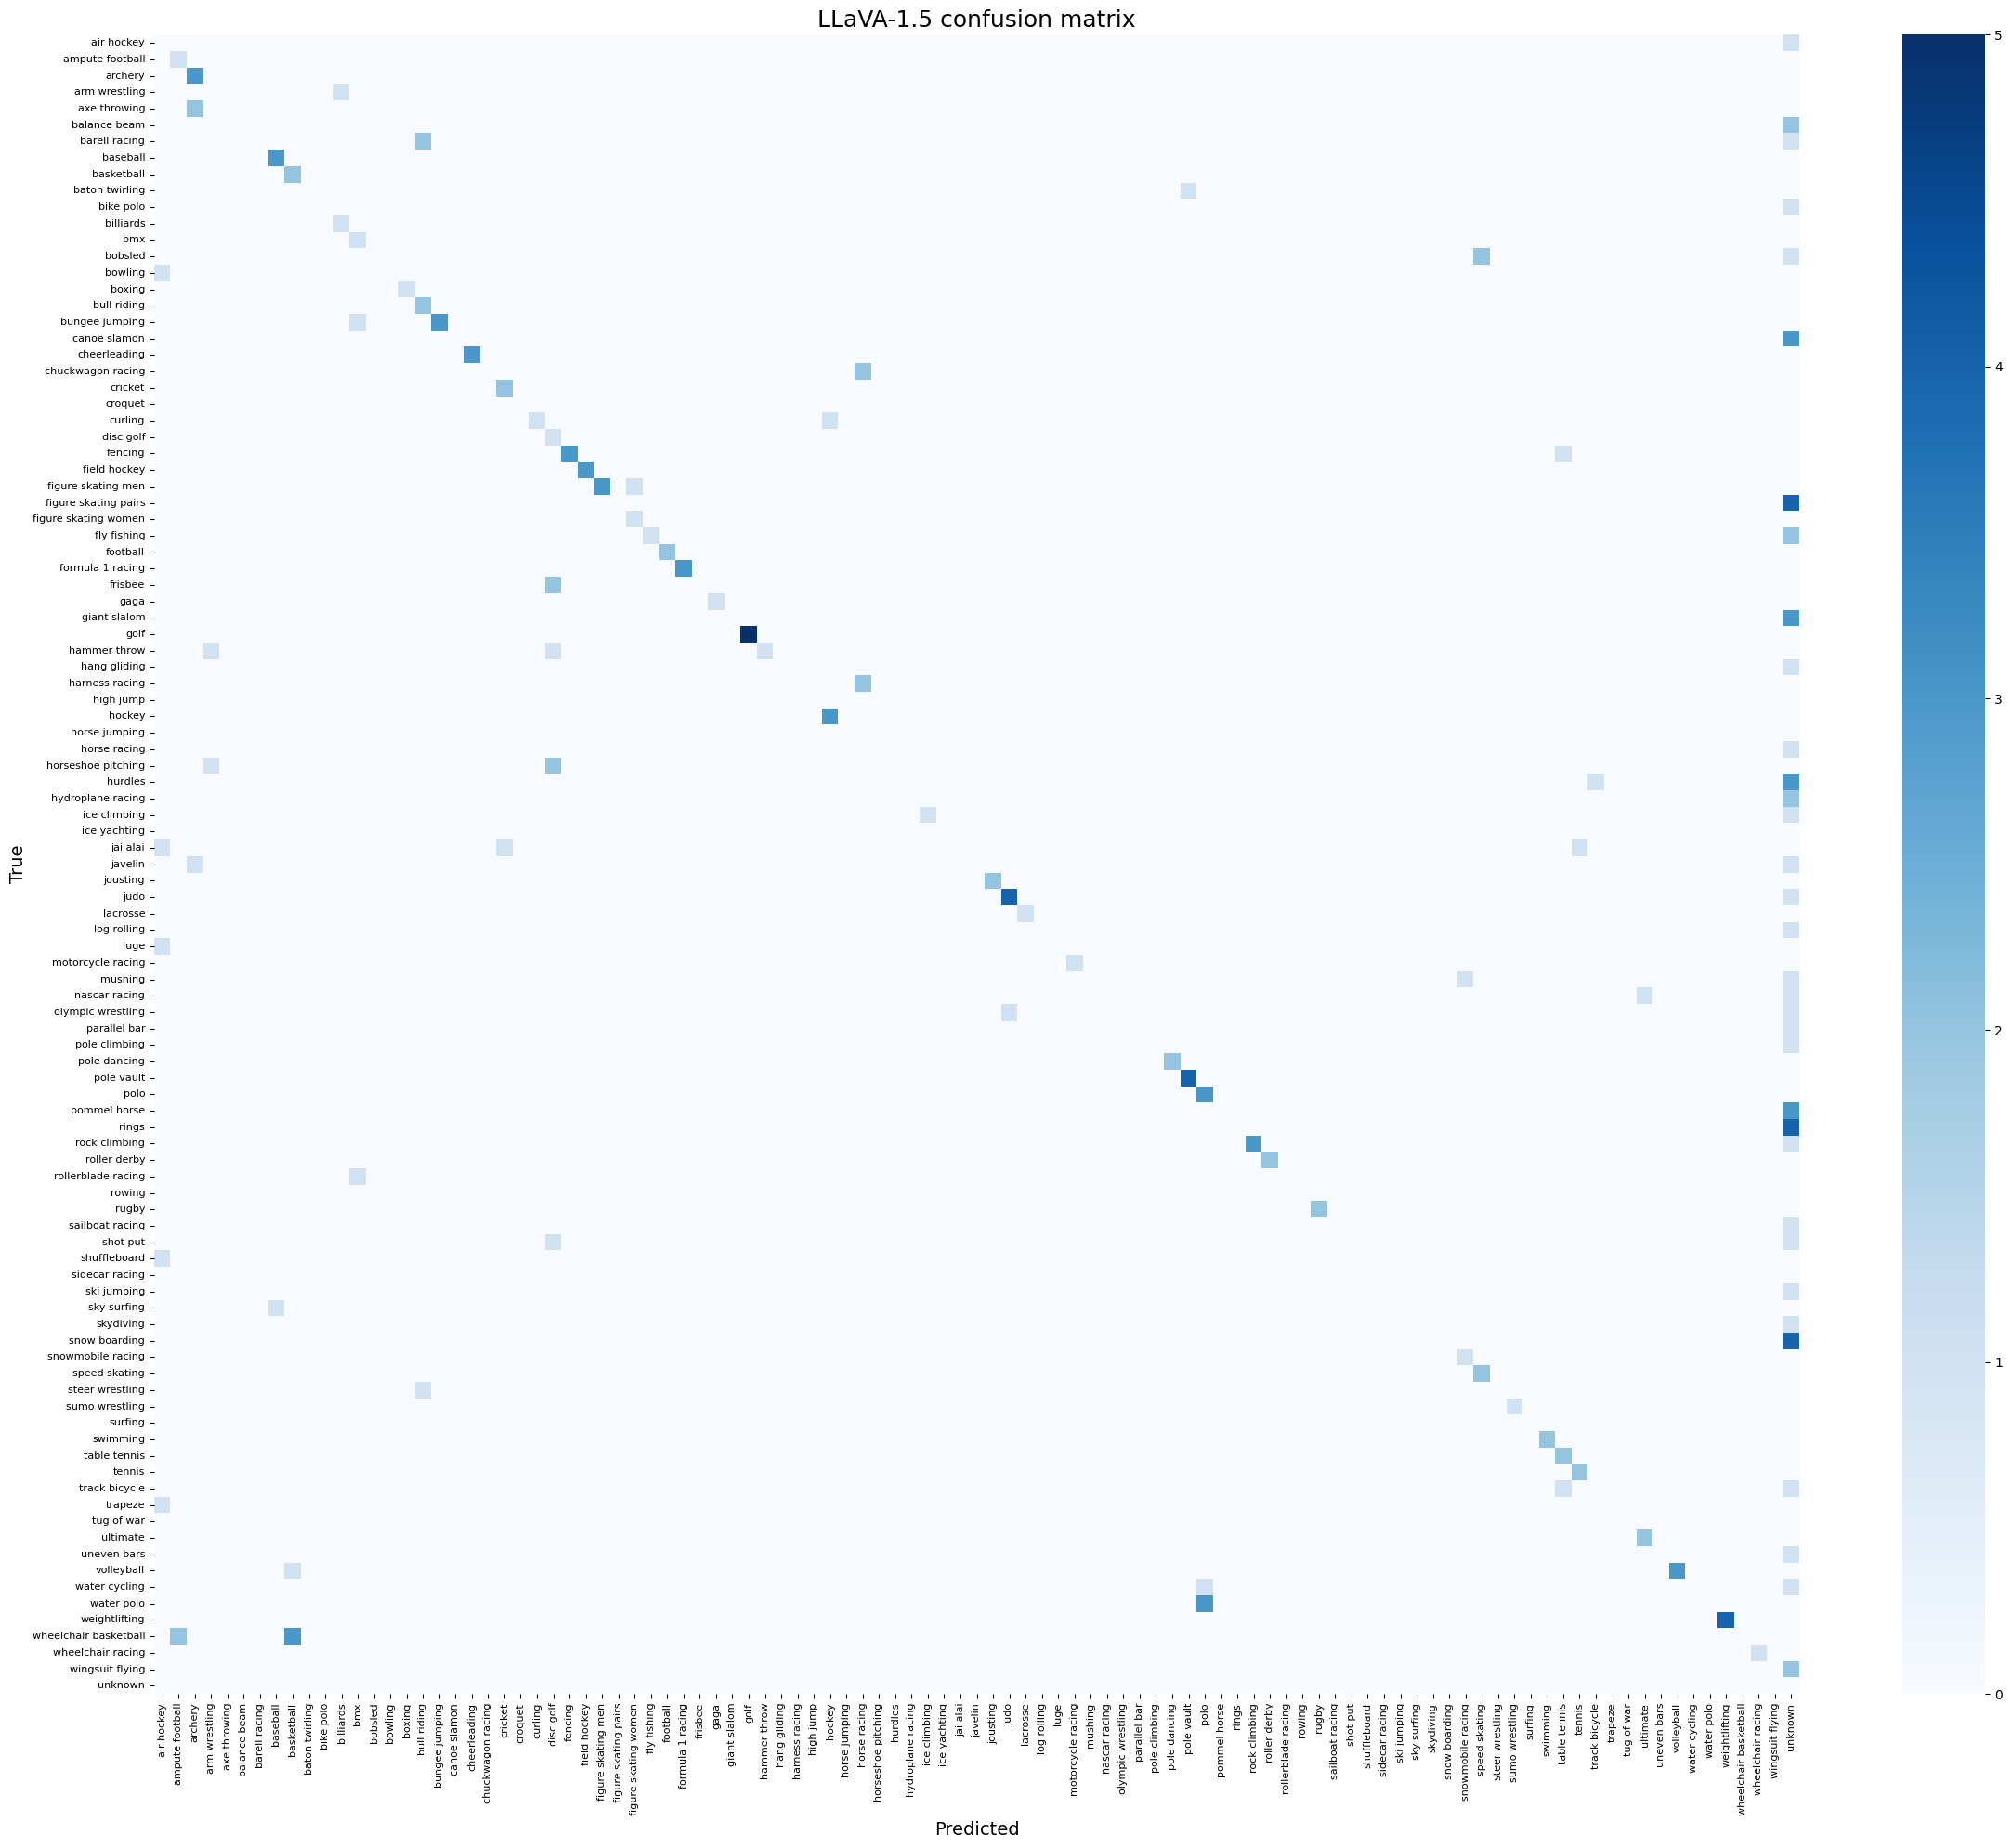


Top confusion pairs (LLaVA 1.5):
       snow boarding -> unknown             : 4
               rings -> unknown             : 4
figure skating pairs -> unknown             : 4
wheelchair basketball -> basketball          : 3
          water polo -> polo                : 3
        pommel horse -> unknown             : 3
             hurdles -> unknown             : 3
        giant slalom -> unknown             : 3


In [ ]:
# Evaluation
y_true_llm = np.array(y_true_llm)
y_pred_llm = np.array(y_pred_llm)

# Handle LLM unknown outputs
llm_classes = classes.copy()
if "unknown" in y_pred_llm and "unknown" not in llm_classes:
    llm_classes.append("unknown")

print(f"Failed extractions/hallucinations: {failed_extractions}\n")

llm_cm = evaluate_predictions(y_true_llm, y_pred_llm, llm_classes, "LLaVA-1.5")

print("\nTop confusion pairs (LLaVA 1.5):")
for count, t, p in top_confusion_pairs(llm_cm, llm_classes, k=8):
    print(f"{t:>20} -> {p:<20}: {count}")

Samples evaluated (excluding 'unknown'): 145
Failed extractions/hallucinations: 55

LLaVA-1.5 - No Unknown accuracy: 0.6552
LLaVA-1.5 - No Unknown macro-F1: 0.5055
LLaVA-1.5 - No Unknown MCC: 0.6535

                       precision    recall  f1-score   support

           air hockey       0.00      0.00      0.00         0
      ampute football       0.33      1.00      0.50         1
              archery       0.50      1.00      0.67         3
        arm wrestling       0.00      0.00      0.00         1
         axe throwing       0.00      0.00      0.00         2
         balance beam       0.00      0.00      0.00         0
        barell racing       0.00      0.00      0.00         2
             baseball       0.75      1.00      0.86         3
           basketball       0.33      1.00      0.50         2
       baton twirling       0.00      0.00      0.00         1
            bike polo       0.00      0.00      0.00         0
            billiards       0.50      1.00 

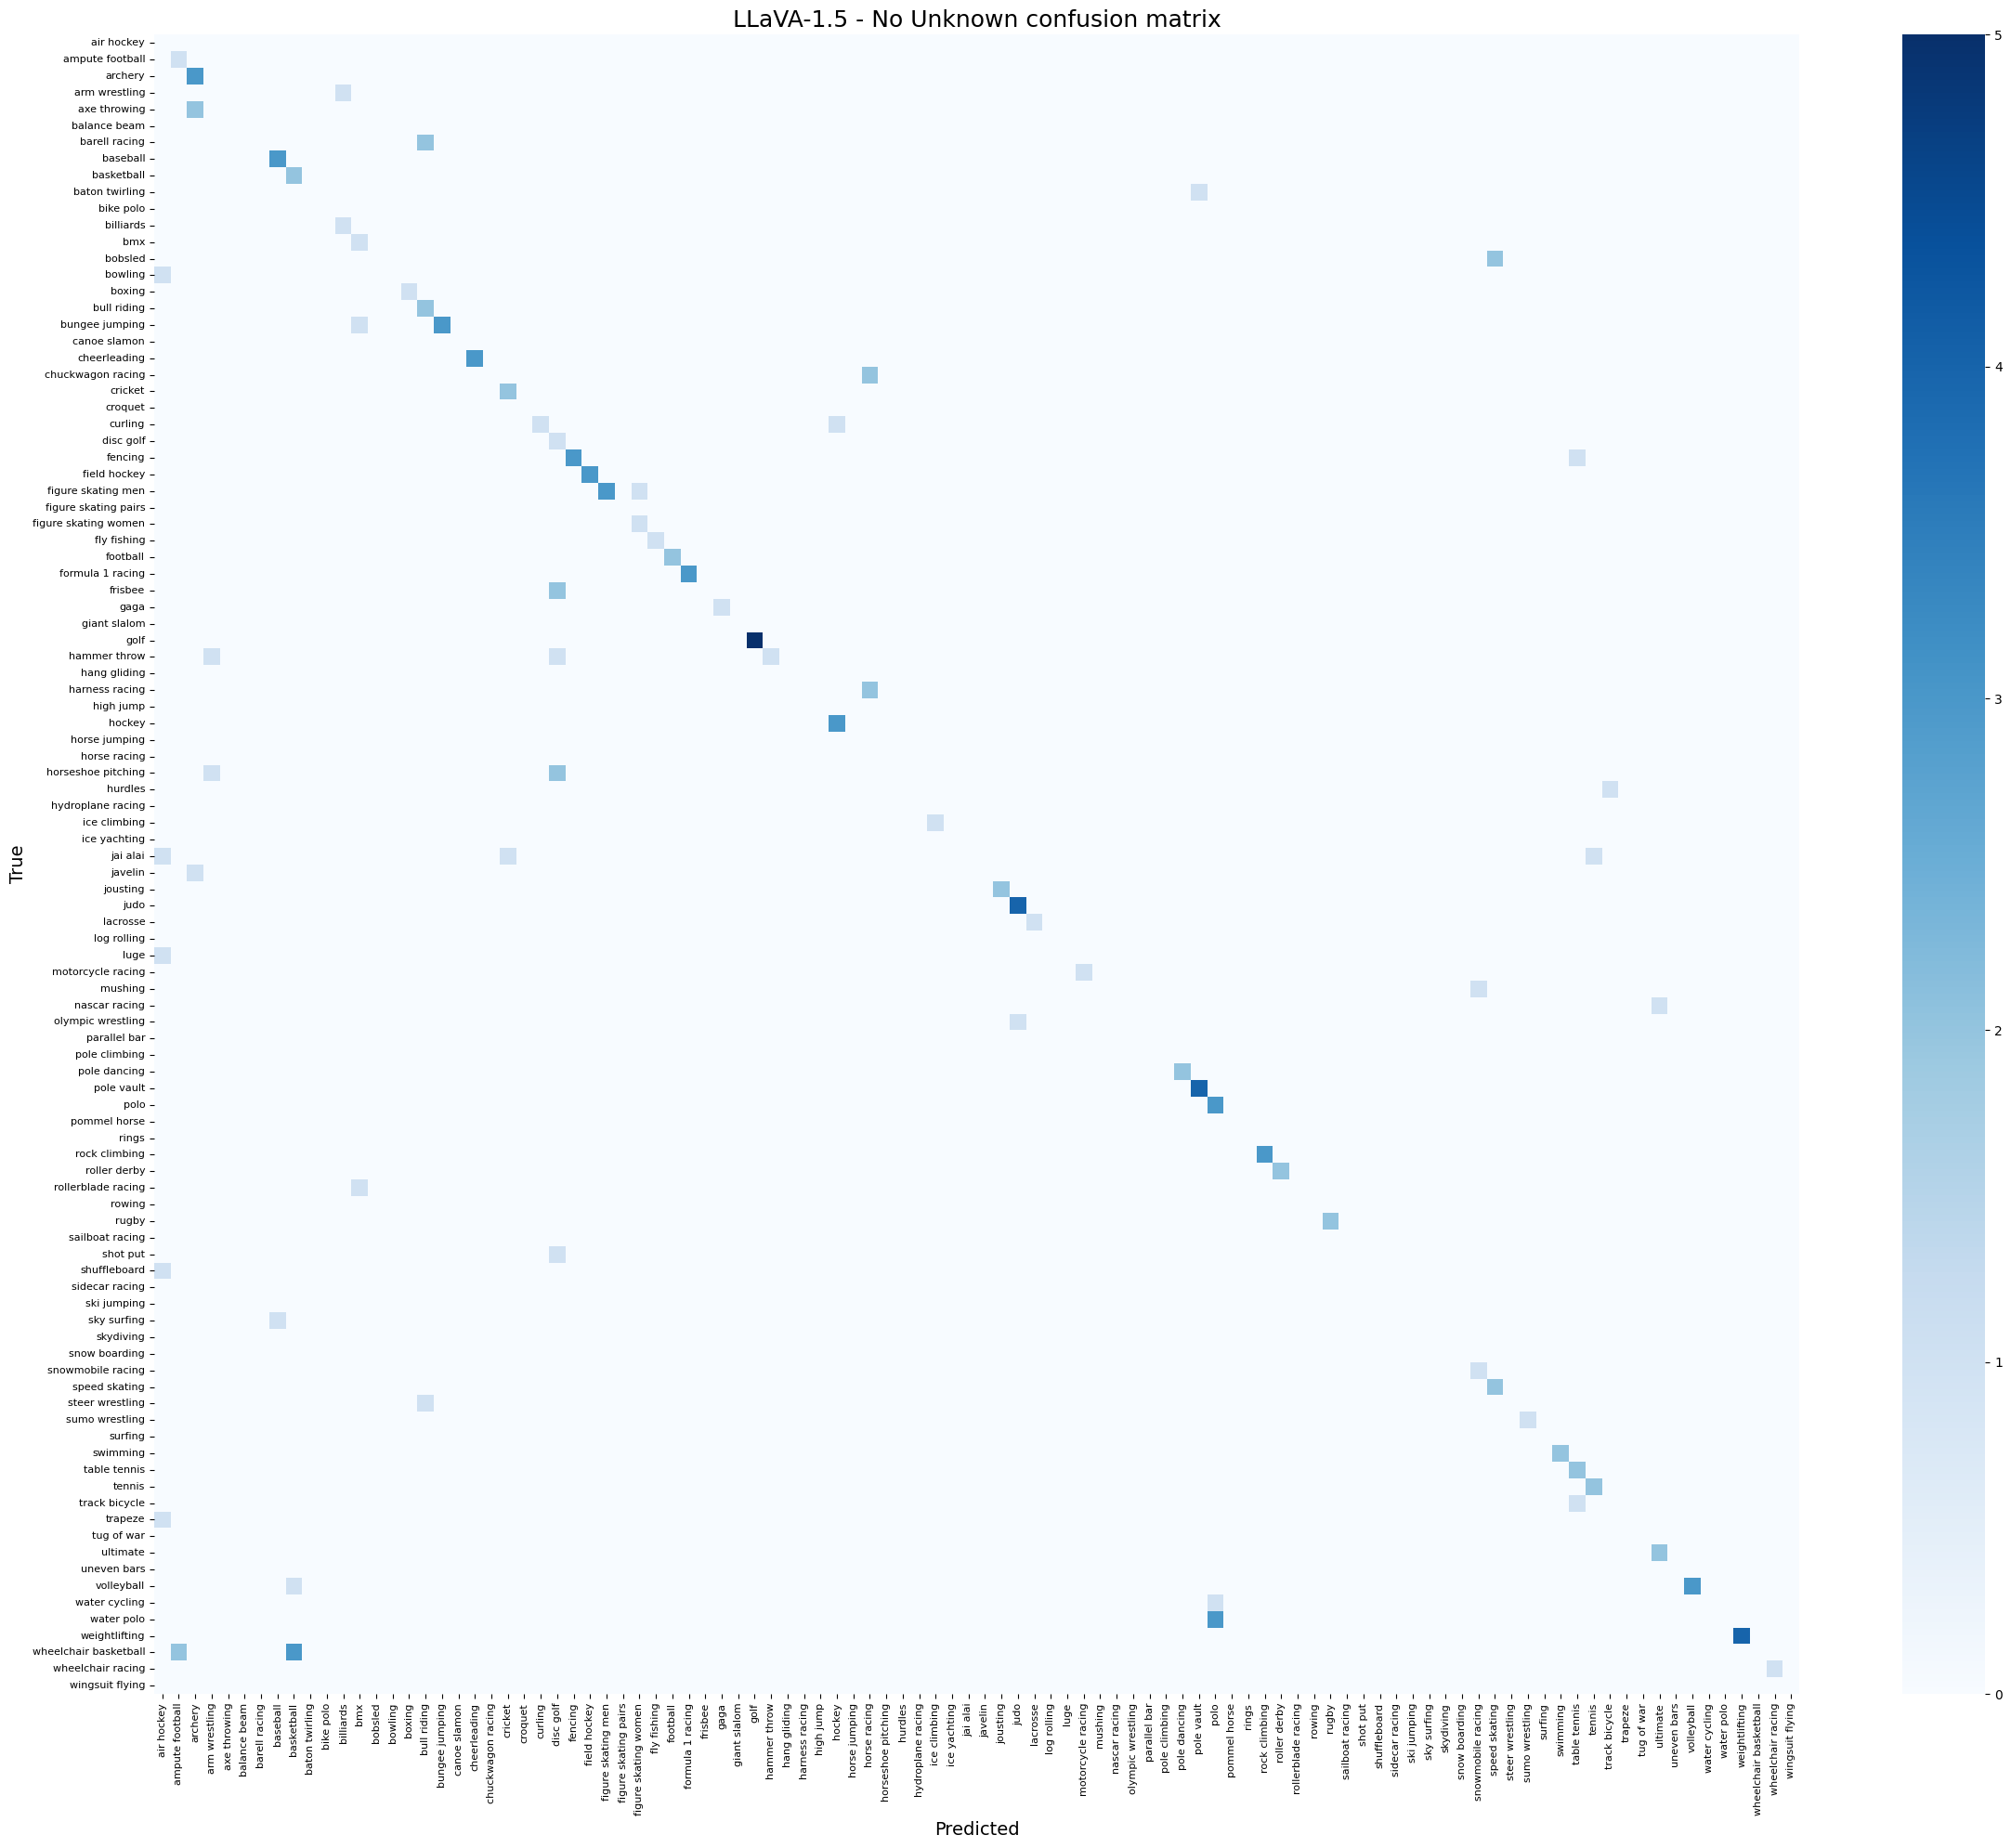


Top confusion pairs (LLaVA 1.5):
wheelchair basketball -> basketball          : 3
          water polo -> polo                : 3
wheelchair basketball -> ampute football     : 2
  horseshoe pitching -> disc golf           : 2
      harness racing -> horse racing        : 2
             frisbee -> disc golf           : 2
   chuckwagon racing -> horse racing        : 2
             bobsled -> speed skating       : 2


In [ ]:
llm_classes = classes.copy()

# Filter out "unknown" outputs
valid_indices = y_pred_llm != "unknown"
y_true_filtered = y_true_llm[valid_indices]
y_pred_filtered = y_pred_llm[valid_indices]

print(f"Samples evaluated (excluding 'unknown'): {len(y_true_filtered)}")
print(f"Failed extractions/hallucinations: {failed_extractions}\n")

llm_cm = evaluate_predictions(y_true_filtered, y_pred_filtered, classes, "LLaVA-1.5 - No Unknown")

print("\nTop confusion pairs (LLaVA 1.5):")
for count, t, p in top_confusion_pairs(llm_cm, classes, k=8):
    print(f"{t:>20} -> {p:<20}: {count}")

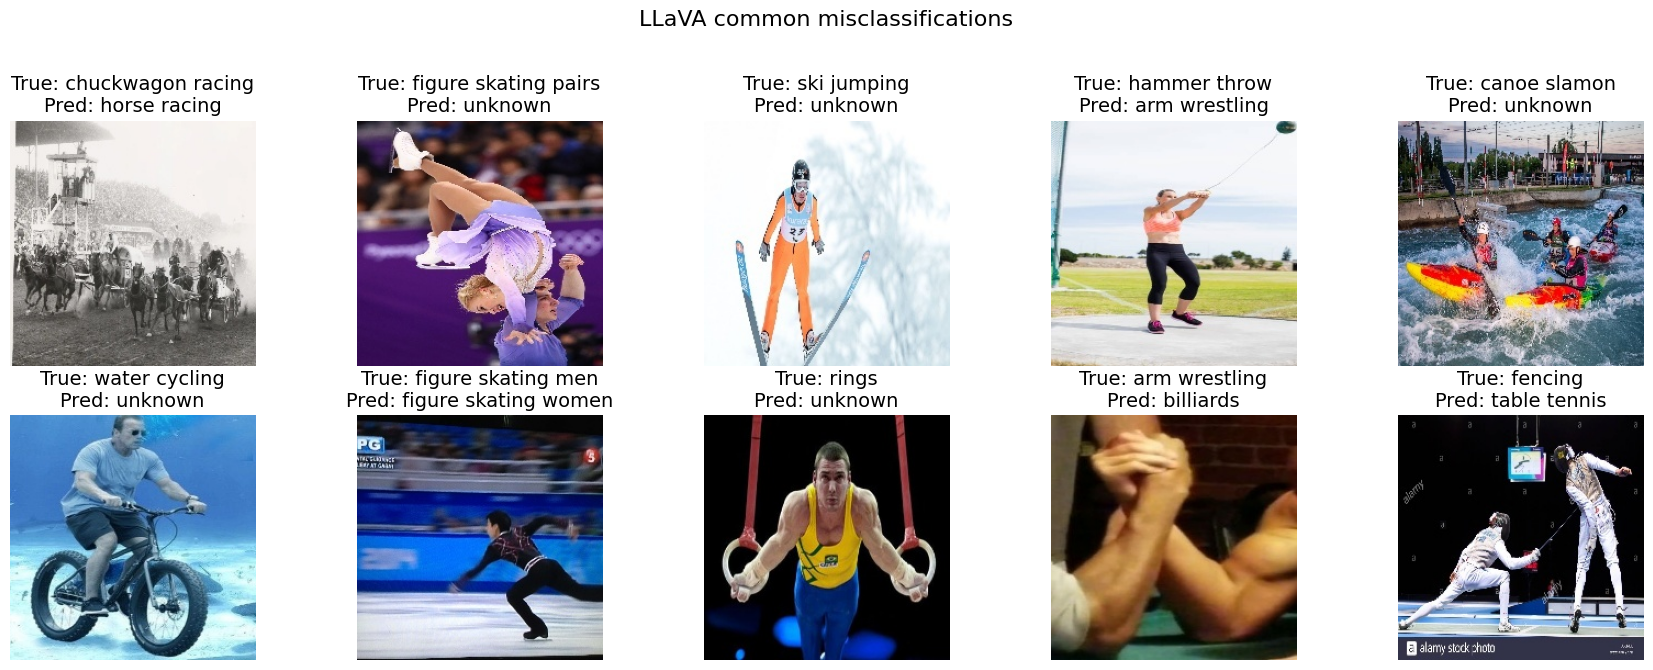

In [ ]:
# Functions modified from cifar final project example
def collect_misclassified_examples_llm(df, y_true, y_pred, max_examples=12):
    wrong_idx = np.where(y_true != y_pred)[0]
    records = []
    for i in wrong_idx:
        records.append({
            "idx": int(i),
            "true": str(y_true[i]),
            "pred": str(y_pred[i]),
        })
    random.shuffle(records)
    return records[:max_examples]

def show_examples_llm(dataset_obj, examples, title, ncols=5):
    if not examples:
        print("No examples to show.")
        return
    n = len(examples)
    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(3.5 * ncols, 3.5 * nrows))
    dataset_obj = dataset_obj.reset_index(drop=True)

    for k, ex in enumerate(examples, start=1):
        img_path = dataset_obj.loc[ex["idx"], 'file_path']
        img = Image.open(img_path).convert('RGB')
        plt.subplot(nrows, ncols, k)
        plt.imshow(img)

        plt.title(f"True: {ex['true']}\nPred: {ex['pred']}", fontsize=14)
        plt.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Failure cases
llm_mis_examples = collect_misclassified_examples_llm(llm_test_df, y_true_llm, y_pred_llm, max_examples=10)
show_examples_llm(llm_test_df, llm_mis_examples, "LLaVA common misclassifications")


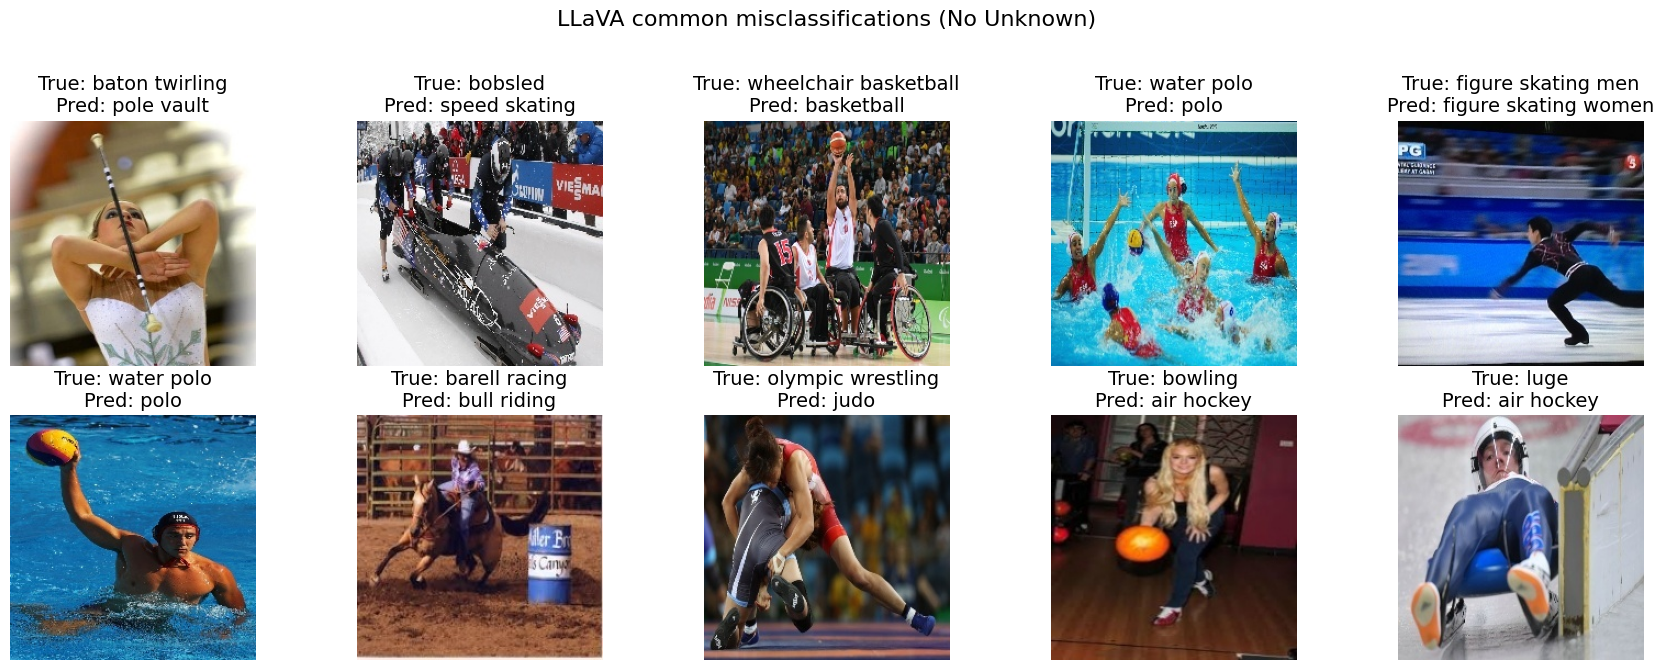

In [ ]:
# Apply "unknown" filter to df
filtered_llm_test_df = llm_test_df[valid_indices].reset_index(drop=True)

y_true_filtered = y_true_llm[valid_indices]
y_pred_filtered = y_pred_llm[valid_indices]

# Failure cases, no "Unknown"
llm_mis_examples = collect_misclassified_examples_llm(filtered_llm_test_df, y_true_filtered, y_pred_filtered, max_examples=10)
show_examples_llm(filtered_llm_test_df, llm_mis_examples, "LLaVA common misclassifications (No Unknown)")
